# Aleatoriedad y números aleatorios avanzados con NumPy

Notebook guiado que acompaña a `11-numpy-aleatoriedad-avanzado.md`.

## La API moderna: `Generator` y `default_rng`

In [5]:
import numpy as np

rng = np.random.default_rng(2026)
print(rng.normal(size=5))

[-0.79312248  0.24057128 -1.89632635  1.39577171  0.63829474]


## Distribuciones continuas

In [6]:
rng = np.random.default_rng(0)
uniformes   = rng.uniform(low=0, high=10, size=5)
normales    = rng.normal(loc=5, scale=2, size=5)
exponencial = rng.exponential(scale=1.0, size=5)
print('uniforme:', uniformes)
print('normal:', normales)
print('exponencial:', exponencial)

uniforme: [6.36961687 2.69786714 0.40973524 0.16527636 8.13270239]
normal: [5.72319011 7.60800009 6.89416193 3.59252953 2.46915706]
exponencial: [3.28642826e+00 1.28775033e-03 2.26909466e+00 7.24976849e-02
 1.06940030e+00]


## Distribuciones discretas

In [7]:
rng = np.random.default_rng(1)
enteros  = rng.integers(low=0, high=10, size=8)
binomial = rng.binomial(n=10, p=0.5, size=8)
poisson  = rng.poisson(lam=3.0, size=8)
print('enteros:', enteros)
print('binomial:', binomial)
print('poisson:', poisson)

enteros: [4 5 7 9 0 1 8 9]
binomial: [4 5 6 5 5 2 6 5]
poisson: [3 2 3 5 3 3 2 5]


### Gráficas de las distribuciones

Visualización de las distribuciones **continuas** (histogramas) y **discretas** (barras) generadas con `default_rng`.

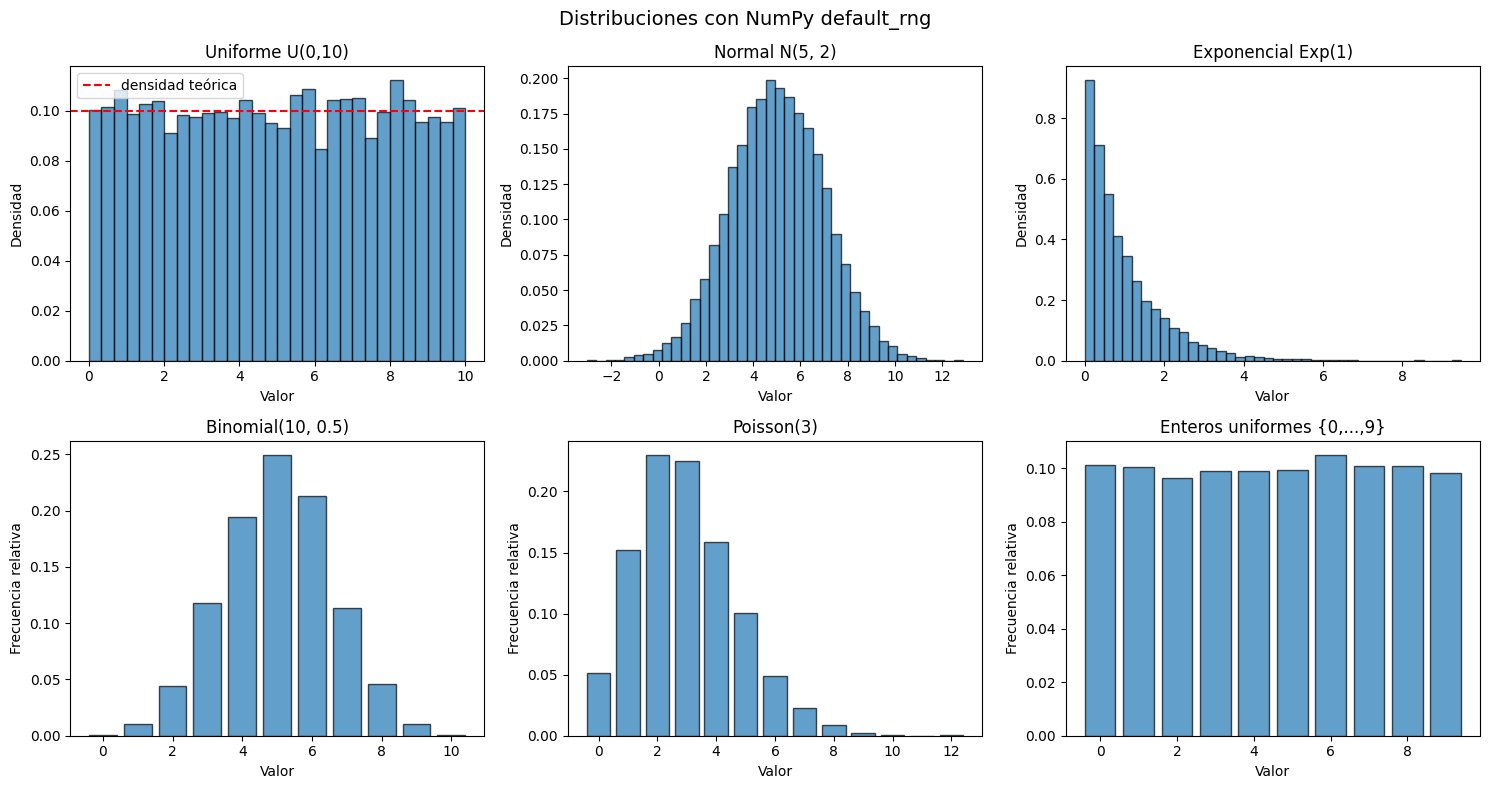

In [8]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
n = 10000

uniformes   = rng.uniform(low=0, high=10, size=n)
normales    = rng.normal(loc=5, scale=2, size=n)
exponencial = rng.exponential(scale=1.0, size=n)
binomial    = rng.binomial(n=10, p=0.5, size=n)
poisson     = rng.poisson(lam=3.0, size=n)

fig, axs = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Distribuciones con NumPy default_rng', fontsize=14)

# Fila 1: distribuciones continuas (histogramas)
axs[0, 0].hist(uniformes, bins=30, density=True, edgecolor='black', alpha=0.7)
axs[0, 0].set_title('Uniforme U(0,10)')
axs[0, 0].set_xlabel('Valor')
axs[0, 0].set_ylabel('Densidad')
axs[0, 0].axhline(0.1, color='red', linestyle='--', label='densidad teórica')
axs[0, 0].legend()

axs[0, 1].hist(normales, bins=40, density=True, edgecolor='black', alpha=0.7)
axs[0, 1].set_title('Normal N(5, 2)')
axs[0, 1].set_xlabel('Valor')
axs[0, 1].set_ylabel('Densidad')

axs[0, 2].hist(exponencial, bins=40, density=True, edgecolor='black', alpha=0.7)
axs[0, 2].set_title('Exponencial Exp(1)')
axs[0, 2].set_xlabel('Valor')
axs[0, 2].set_ylabel('Densidad')

# Fila 2: distribuciones discretas (barras de frecuencias)
for i, (datos, titulo) in enumerate([(binomial, 'Binomial(10, 0.5)'), (poisson, 'Poisson(3)')]):
    valores, counts = np.unique(datos, return_counts=True)
    axs[1, i].bar(valores, counts / n, edgecolor='black', alpha=0.7)
    axs[1, i].set_title(titulo)
    axs[1, i].set_xlabel('Valor')
    axs[1, i].set_ylabel('Frecuencia relativa')

enteros = rng.integers(low=0, high=10, size=n)
valores, counts = np.unique(enteros, return_counts=True)
axs[1, 2].bar(valores, counts / n, edgecolor='black', alpha=0.7)
axs[1, 2].set_title('Enteros uniformes {0,...,9}')
axs[1, 2].set_xlabel('Valor')
axs[1, 2].set_ylabel('Frecuencia relativa')

plt.tight_layout()
plt.show()

## Selección y permutación: `choice`, `shuffle`, `permutation`

In [24]:
rng = np.random.default_rng(42)
datos = np.arange(10)
print(datos)
print()
barajado = rng.permutation(datos)
print(barajado)
print()
muestra  = rng.choice(np.arange(20), size=5, replace=False)

print('permutación:', barajado)
print('choice sin repetición:', muestra)
print(barajado)
print('permutación 2',rng.permutation(barajado))
print(barajado)

rng.shuffle(barajado)
print(barajado)

[0 1 2 3 4 5 6 7 8 9]

[5 6 0 7 3 2 4 9 1 8]

permutación: [5 6 0 7 3 2 4 9 1 8]
choice sin repetición: [10 17 12 14 11]
[5 6 0 7 3 2 4 9 1 8]
permutación 2 [9 5 3 0 7 2 1 6 8 4]
[5 6 0 7 3 2 4 9 1 8]
[4 8 6 2 3 5 1 9 7 0]


In [30]:
rng = np.random.default_rng(71)
categorias = np.array(['a', 'b', 'c'])
probs = np.array([0.5, 0.3, 0.2])
eleccion = rng.choice(categorias, size=100, p=probs)
freq = np.unique(eleccion, return_counts=True)[1] / 100
print('frecuencias aprox.:', freq)

frecuencias aprox.: [0.52 0.29 0.19]


## Reproducibilidad: misma semilla y orden

In [21]:
r1 = np.random.default_rng(42)
r2 = np.random.default_rng(42)
print('¿mismas secuencias?', np.array_equal(r1.normal(size=4), r2.normal(size=4)))

¿mismas secuencias? True


## Semillas por bloque

In [25]:
def experimento(semilla):
    rng = np.random.default_rng(semilla)
    return rng.normal(loc=0, scale=1, size=1000).mean()

medias = [experimento(s) for s in range(5)]
print(medias)

[np.float64(-0.04802827676298692), np.float64(-0.05425322276336561), np.float64(-0.022409060642830412), np.float64(0.03847915576789472), np.float64(-0.009792906124977931)]


## Split entrenamiento / test

In [26]:
rng = np.random.default_rng(10)
n = 100
indices = rng.permutation(n)
punto = int(n * 0.8)
train_idx, test_idx = indices[:punto], indices[punto:]
print('train:', len(train_idx), 'test:', len(test_idx))

train: 80 test: 20


## Dataset 2D: barajar bien vs. mal

Tenemos un dataset con **características** `X` (una fila por muestra) y sus **etiquetas** `y`.
Si las barajamos por separado, **rompemos la correspondencia fila-etiqueta**: cada fila de `X` queda
asociada a la etiqueta de otra muestra. La clave es barajar **los índices una sola vez** y aplicarlos
a `X` y a `y` por igual.

In [ ]:
import numpy as np

rng = np.random.default_rng(0)
n = 10
X = np.arange(n * 3).reshape(n, 3)
y = np.arange(n)
print('X (3 características, 10 muestras):\n', X)
print('y (etiquetas):', y)

### ❌ MAL: barajar `X` y `y` por separado

Cada barajado usa una permutación distinta, así que las filas de `X` ya no coinciden con sus etiquetas.

In [ ]:
rng = np.random.default_rng(0)
X_mal = rng.permutation(X)   # permutación A sobre las filas
rng.permutation(X)  # 'gasta' la siguiente permutación en otra tirada
y_mal = rng.permutation(y)   # permutación B distinta sobre las etiquetas

print('X_mal (filas barajadas por separado):\n', X_mal)
print('y_mal (etiquetas barajadas por separado):', y_mal)
print()
print('ERROR: la primera muestra ahora tiene estas características X_mal[0] =', X_mal[0],
      'pero la etiqueta y_mal[0] =', y_mal[0], 'que NO es la suya original (0).')

### ✅ BIEN: barajar los índices una sola vez

Generamos **una única permutación de índices** y la aplicamos a `X` y a `y`. Así cada
fila conserva su etiqueta, solo cambia el orden de las muestras.

In [ ]:
rng = np.random.default_rng(0)
idx = rng.permutation(n)   # una sola permutación de índices
X_bien = X[idx]
y_bien = y[idx]

print('índices barajados (1 sola vez):', idx)
print('X_bien:\n', X_bien)
print('y_bien:', y_bien)
print()
# Verificación: cada fila i conserva su etiqueta original
ok = all(np.array_equal(X_bien[k], X[idx[k]]) and y_bien[k] == y[idx[k]] for k in range(n))
print('La primera muestra X_bien[0] =', X_bien[0], 'sigue con su etiqueta y_bien[0] =', y_bien[0])
print('Cada fila conserva su etiqueta original:', ok)

### 🧪 Demostración del fallo con un ejemplo pequeño

Barajar por separado deja a la primera muestra con la etiqueta de OTRA muestra. Para verlo,
repetimos el barajado mal hecho y comparamos el par (fila, etiqueta) con el original.

In [ ]:
rng = np.random.default_rng(0)
X = np.arange(10 * 2).reshape(10, 2)   # dataset minúsculo, 2 características
y = np.arange(10)

# MAL
Xm, ym = rng.permutation(X), rng.permutation(y)
# BIEN
idx = rng.permutation(10)
Xb, yb = X[idx], y[idx]

print('original: fila0', X[0], 'étiqueta', y[0])
print('MAL   -> fila0', Xm[0], 'étiqueta', ym[0], ' <- corrupción visible')
print('BIEN  -> fila0', Xb[0], 'étiqueta', yb[0], ' (es la fila', idx[0], 'original)')

print()
print('En el barajado correcto, la etiqueta y_bien[k] es la etiqueta original de la fila que ocupa la posición k:')
for k in [0, 3, 9]:
    print(f'  posición {k}: fila=X_bien[{k}]={Xb[k]}  -> etiqueta original de {idx[k]} = {yb[k]}')

# Errores frecuentes

1. Usar la API global (`np.random.rand`) mezclada con `Generator`; fija uno solo.
2. Olvidar la semilla y no poder reproducir el experimento.
3. Barajar el dataset **y sus etiquetas por separado** (se pierde la correspondencia).
4. No distinguir `shuffle` (in-place) de `permutation` (copia).
5. Llamar métodos en distinto orden entre dos copias con la misma semilla y esperar
  idéntico resultado.
6. Suponer que la media/desviación empírica de una muestra pequeña coincide con los
  parámetros de la distribución (depende del tamaño).

## Ejercicios

1. Con semilla `0`, genera 1000 `uniform(0,1)` y comprueba media ≈ 0.5.
2. Genera 1000 `poisson(3)` y compara su media con 3.
3. Repite una división 80/20 con la misma semilla dos veces y verifica que coincide.
4. Baraja un dataset 2D conservando la correspondencia fila-etiqueta.
5. Explica por qué no debes barajar características y etiquetas por separado.